# OLMo 3 7B NanoReason benchmark analysis

**Base → SFT → repetition SFT → Dr. GRPO (RLVR)**,  benchmarked on:
GPQA, MATH-500, AIME 2024, AIME 2025, BBH and IFEval.


### Run the notebook without syncing all dependencies:

```bash
uv sync --only-group notebooks
```

## Model stages

| Stage | Results directory | Training |
|:--|:--|:--|
| Base | [`Olmo-3-7B`](https://huggingface.co/allenai/Olmo-3-1025-7B) | Original pretrained OLMo-3-1025-7B |
| SFT | `NanoReason-7B-SFT` | 6,000 optimizer steps of SFT |
| Refined | `NanoReason-7B-SFT-Refined` | 16 epochs of repetition SFT |
| Think (RLVR) | `NanoReason-7B-Think` | 512 optimizer steps of Dr. GRPO |

<!-- TODO: link other models once hf repos are online -->

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

ROOT = Path.cwd().parent

from utils.config import (
    BENCHMARKS,
    COLORS,
    METRIC_LABELS,
    PASS_K,
    STAGES,
    TITLES,
)

from utils import data, style

FIGURES = Path("figures")
style.set_style()

runs, metrics = data.load_metrics(ROOT / "results")
scores = data.score_table(metrics)
tokens = data.load_tokens(ROOT / "results", runs)

## Eval settings

There are no BBH scores for the base model. Benching it on BBH for ~34 hours would not only be a tremendous waste of compute, but also generate mainly garbage.

GPQA requests 131,072 generation tokens but the saved model limit is 32,768.

In [5]:
columns = {
    "num_instances": "Questions",
    "metric": "Metric",
    "repeats": "Samples/question",
    "temperature": "Temperature",
    "top_p": "Top-p",
    "requested_max_gen_toks": "Generation limit",
    "model_max_length": "Model limit",
}
display(
    metrics[["benchmark", *columns]]
    .drop_duplicates()
    .set_index("benchmark")
    .reindex(BENCHMARKS)
    .rename(index=TITLES, columns=columns)
)

,Questions,Metric,Samples/question,Temperature,Top-p,Generation limit,Model limit
benchmark,,,,,,,
GPQA Main,448,exact_match,1,0.6,0.95,131072,32768
MATH-500,500,exact_match_flex,1,0.7,NaN,32768,32768
AIME 2024,30,pass_at_1,32,0.6,0.95,16384,32768
AIME 2025,30,pass_at_1,32,0.6,0.95,16384,32768
BBH,6511,micro,1,0.6,0.95,32768,32768
IFEval,541,prompt_level_loose_acc,1,0.6,0.95,32768,32768


## Benchmark scores

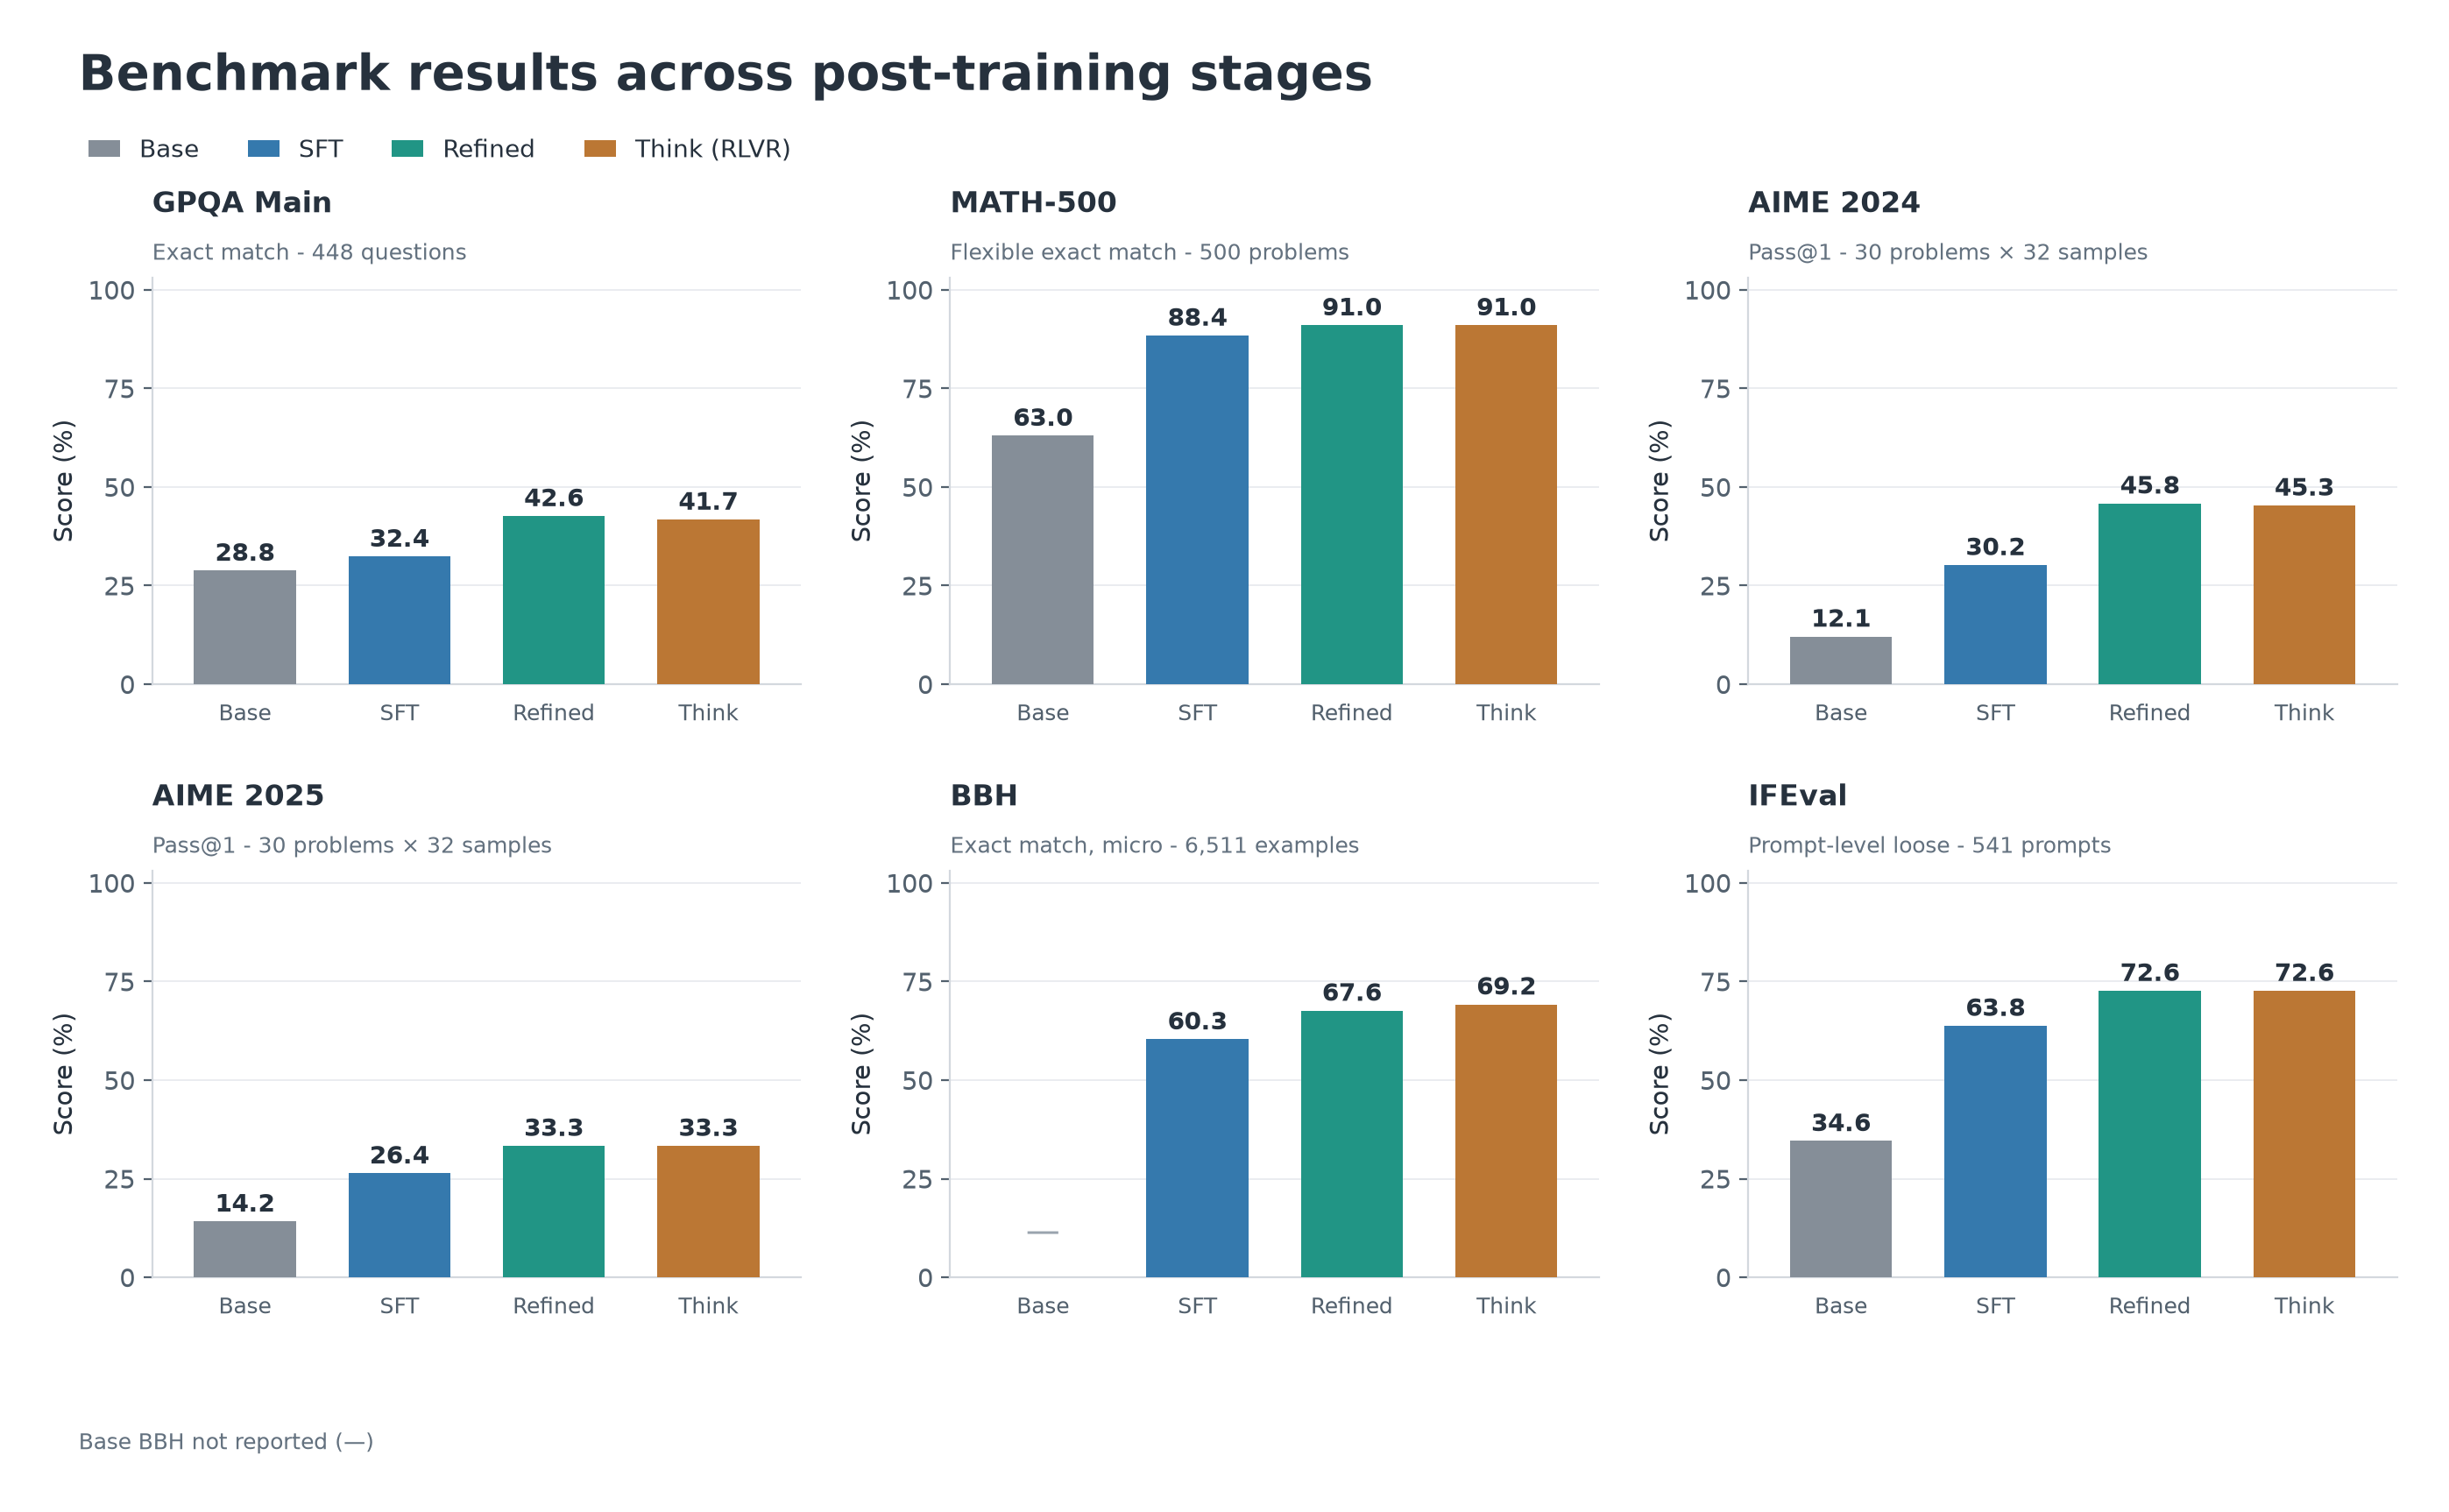

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9.2))
fig.subplots_adjust(
    left=0.065, right=0.98, top=0.76, bottom=0.14, wspace=0.23, hspace=0.46
)
fig.suptitle(
    "Benchmark results across post-training stages",
    x=0.035,
    y=0.9,
    ha="left",
    fontsize=20,
    fontweight="bold",
)
style.stage_legend(fig, y=0.86)
for ax, b in zip(axes.flat, BENCHMARKS):
    ax.set_title(TITLES[b], loc="left", pad=27)
    ax.text(
        0,
        1.045,
        METRIC_LABELS[b],
        transform=ax.transAxes,
        fontsize=9,
        color="#63717F",
    )
    vals = scores.loc[b].to_numpy()
    for i, (s, v) in enumerate(zip(STAGES, vals)):
        if np.isnan(v):
            ax.text(i, 9, "—", ha="center", fontsize=14, color="#9AA4AE")
            continue
        ax.bar(i, v, width=0.66, color=COLORS[s], zorder=3)
        ax.text(i, v + 2.5, f"{v:.1f}", ha="center", fontsize=10, weight="bold")
    ax.set(ylim=(0, 103), xlim=(-0.6, 3.6), yticks=[0, 25, 50, 75, 100])
    ax.set_xticks(range(4), ["Base", "SFT", "Refined", "Think"], fontsize=9)
    ax.set_ylabel("Score (%)")
    ax.grid(axis="y")
    ax.tick_params(axis="x", length=0, pad=8)
style.footer(
    fig,
    "Base BBH not reported (—)",
)
style.save(fig, FIGURES / "01_benchmark_overview")

## Score changes

Differences in percentage points.

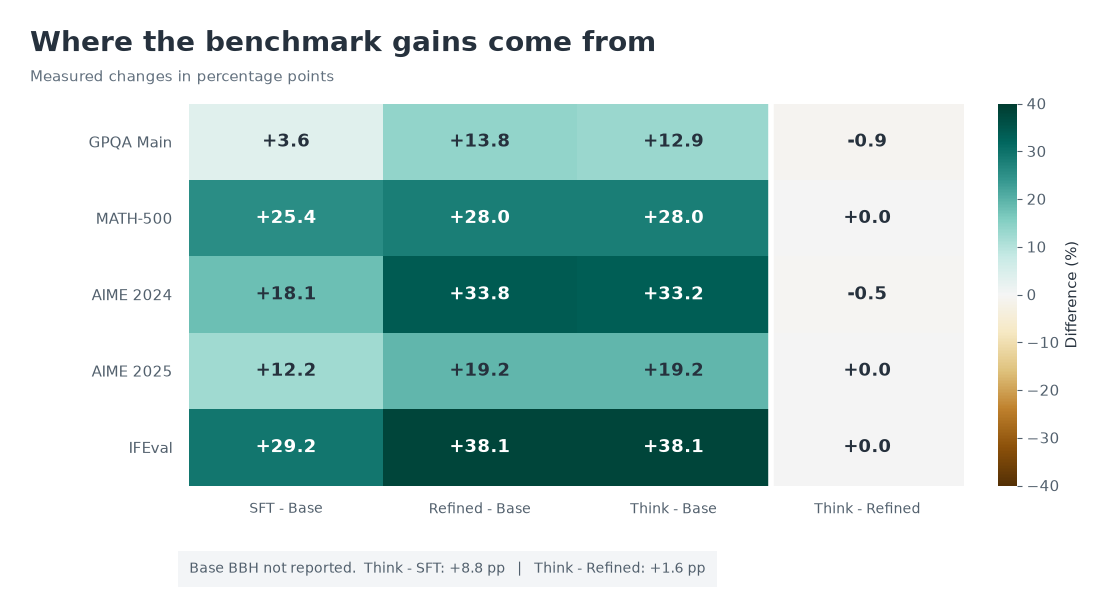

In [10]:
changes = pd.DataFrame(
    {
        "SFT - Base": scores["SFT"] - scores["Base"],
        "Refined - Base": scores["Refined"] - scores["Base"],
        "Think - Base": scores["Think (RLVR)"] - scores["Base"],
        "Think - Refined": scores["Think (RLVR)"] - scores["Refined"],
    }
)
base_deltas = changes.drop(index="bbh")
fig, ax = plt.subplots(figsize=(11.8, 6.7))
fig.subplots_adjust(left=0.17, right=0.88, top=0.82, bottom=0.25)
fig.suptitle(
    "Where the benchmark gains come from",
    x=0.035,
    y=0.93,
    ha="left",
    fontsize=20,
    fontweight="bold",
)
fig.text(
    0.035,
    0.87,
    "Measured changes in percentage points",
    va="top",
    fontsize=10.5,
    color="#63717F",
)
im = ax.imshow(
    base_deltas.to_numpy(),
    cmap="BrBG",
    norm=TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40),
    aspect="auto",
)
for (i, j), v in np.ndenumerate(base_deltas.to_numpy()):
    ax.text(
        j,
        i,
        f"{v:+.1f}",
        ha="center",
        va="center",
        fontsize=13,
        weight="bold",
        color="white" if abs(v) > 25 else "#26313D",
    )
ax.set_xticks(range(4), base_deltas.columns, fontsize=10)
ax.set_yticks(range(5), [TITLES[b] for b in base_deltas.index])
ax.tick_params(length=0, pad=12)
ax.axvline(2.5, color="white", lw=4)
for sp in ax.spines.values():
    sp.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.04)
cbar.set_label("Difference (%)")
cbar.outline.set_visible(False)
bbh_sft = scores.loc["bbh", "Think (RLVR)"] - scores.loc["bbh", "SFT"]
bbh_ref = scores.loc["bbh", "Think (RLVR)"] - scores.loc["bbh", "Refined"]
fig.text(
    0.17,
    0.12,
    f"Base BBH not reported.  Think - SFT: {bbh_sft:+.1f} pp   |   Think - Refined: {bbh_ref:+.1f} pp",
    fontsize=10,
    color="#52606D",
    bbox={"facecolor": "#F3F5F7", "edgecolor": "none", "pad": 8},
)
style.save(fig, FIGURES / "02_stage_deltas")

## Scorecard

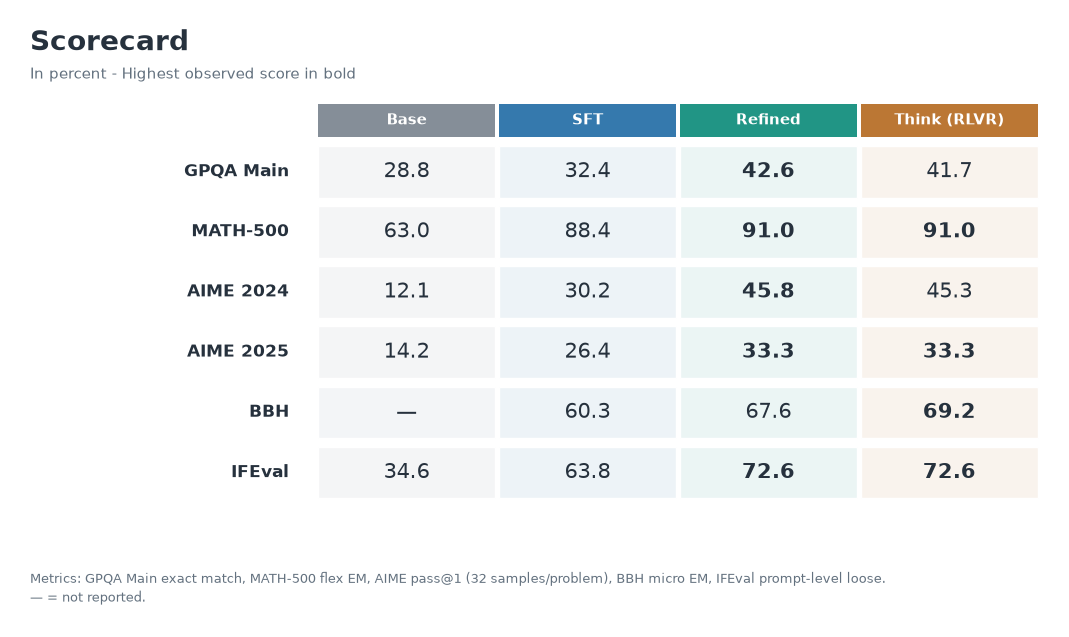

In [31]:
fig, ax = plt.subplots(figsize=(10.8, 6.4))
fig.subplots_adjust(left=0.30, right=0.97, top=0.82, bottom=0.19)
fig.suptitle("Scorecard", x=0.035, y=0.93, ha="left", fontsize=20, fontweight="bold")
fig.text(
    0.035,
    0.87,
    "In percent - Highest observed score in bold",
    va="top",
    fontsize=10.5,
    color="#63717F",
)
ax.set(xlim=(-0.5, 3.5), ylim=(5.5, -1.2))
ax.axis("off")
for j, s in enumerate(STAGES):
    ax.add_patch(
        Rectangle((j - 0.49, -1.12), 0.98, 0.55, facecolor=COLORS[s], edgecolor="none")
    )
    ax.text(
        j,
        -0.85,
        s,
        ha="center",
        va="center",
        color="white",
        weight="bold",
        fontsize=10.5,
    )
for i, b in enumerate(BENCHMARKS):
    ax.text(-0.65, i, TITLES[b], ha="right", va="center", fontsize=12, weight="bold")
    best = scores.loc[b].max()
    for j, s in enumerate(STAGES):
        v = scores.loc[b, s]
        ax.add_patch(
            Rectangle(
                (j - 0.49, i - 0.43),
                0.98,
                0.86,
                facecolor=mpl.colors.to_rgba(COLORS[s], 0.085),
                edgecolor="white",
            )
        )
        if pd.isna(v):
            ax.add_patch(
                Rectangle(
                    (j - 0.49, i - 0.43),
                    0.98,
                    0.86,
                    facecolor="#F3F5F7",
                    edgecolor="white",
                )
            )
            text = "—"
        else:
            text = f"{v:.1f}"
        ax.text(
            j,
            i,
            text,
            ha="center",
            va="center",
            fontsize=15,
            weight="bold" if v == best else "normal",
        )
style.footer(
    fig,
    "Metrics: GPQA Main exact match, MATH-500 flex EM, AIME pass@1 (32 samples/problem), BBH micro EM, IFEval prompt-level loose.\n— = not reported.",
)
style.save(fig, FIGURES / "03_results_scorecard")

## AIME pass@k

Oracle solve coverage across k sampled answers; 30 problems per year, 32 samples per problem.

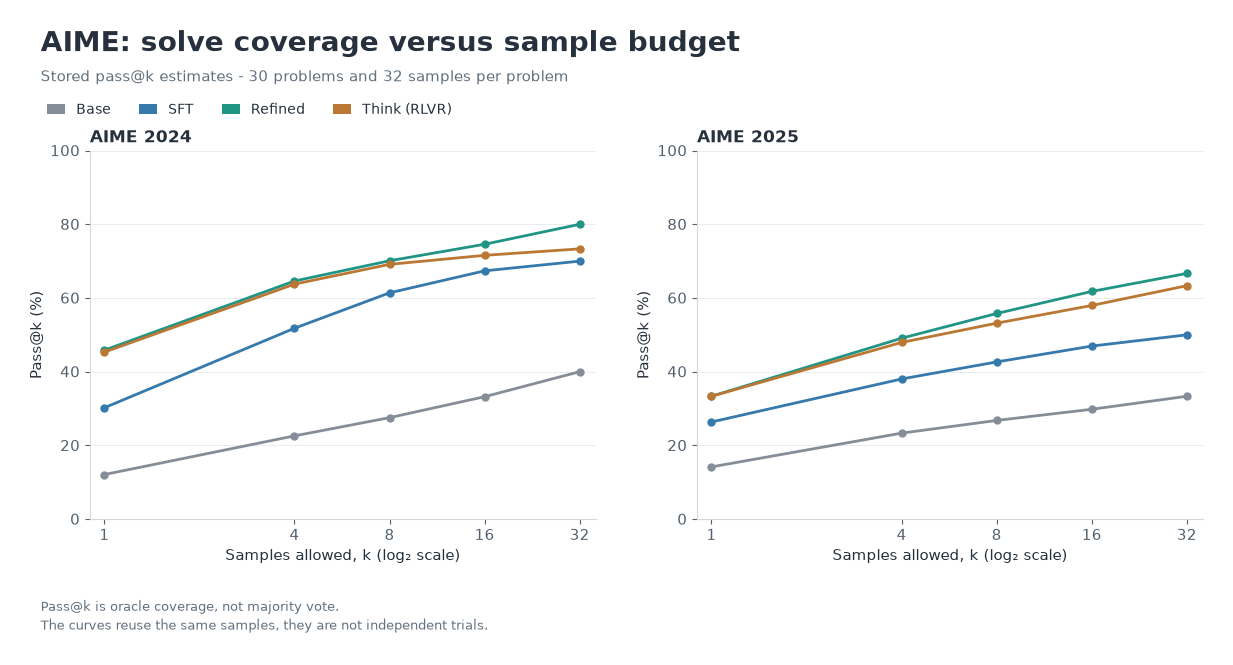

In [33]:
aime = pd.DataFrame(
    {
        "benchmark": TITLES[benchmark],
        "stage": stage,
        **{
            f"pass@{k}": 100
            * runs[stage, benchmark]["tasks"][0]["metrics"][f"pass_at_{k}"]
            for k in PASS_K
        },
    }
    for benchmark in ["aime-2024", "aime-2025"]
    for stage in STAGES
)
values = aime.set_index(["benchmark", "stage"])
fig, axes = plt.subplots(1, 2, figsize=(12.3, 6.7))
fig.subplots_adjust(left=0.075, right=0.98, top=0.75, bottom=0.20, wspace=0.20)
fig.suptitle(
    "AIME: solve coverage versus sample budget",
    x=0.035,
    y=0.93,
    ha="left",
    fontsize=20,
    fontweight="bold",
)
fig.text(
    0.035,
    0.87,
    "Stored pass@k estimates - 30 problems and 32 samples per problem",
    va="top",
    fontsize=10.5,
    color="#63717F",
)
style.stage_legend(fig)
ks = PASS_K
for ax, b in zip(axes, ["aime-2024", "aime-2025"]):
    for s in STAGES:
        vals = values.loc[(TITLES[b], s), [f"pass@{k}" for k in ks]].to_numpy(
            dtype=float
        )
        ax.plot(ks, vals, "o-", color=COLORS[s], lw=2, ms=5, label=s)
    ax.set_xscale("log", base=2)
    ax.set_xticks(ks, [str(k) for k in ks])
    ax.set(ylim=(0, 100), yticks=np.arange(0, 101, 20), xlim=(0.9, 36))
    ax.set_title(TITLES[b], loc="left")
    ax.set_xlabel("Samples allowed, k (log₂ scale)")
    ax.set_ylabel("Pass@k (%)")
    ax.grid(axis="y")
style.footer(
    fig,
    "Pass@k is oracle coverage, not majority vote.\nThe curves reuse the same samples, they are not independent trials.",
)
style.save(fig, FIGURES / "04_aime_pass_at_k")

## Score vs. tokens

Mean generated tokens per response. Arrows follow training stages.

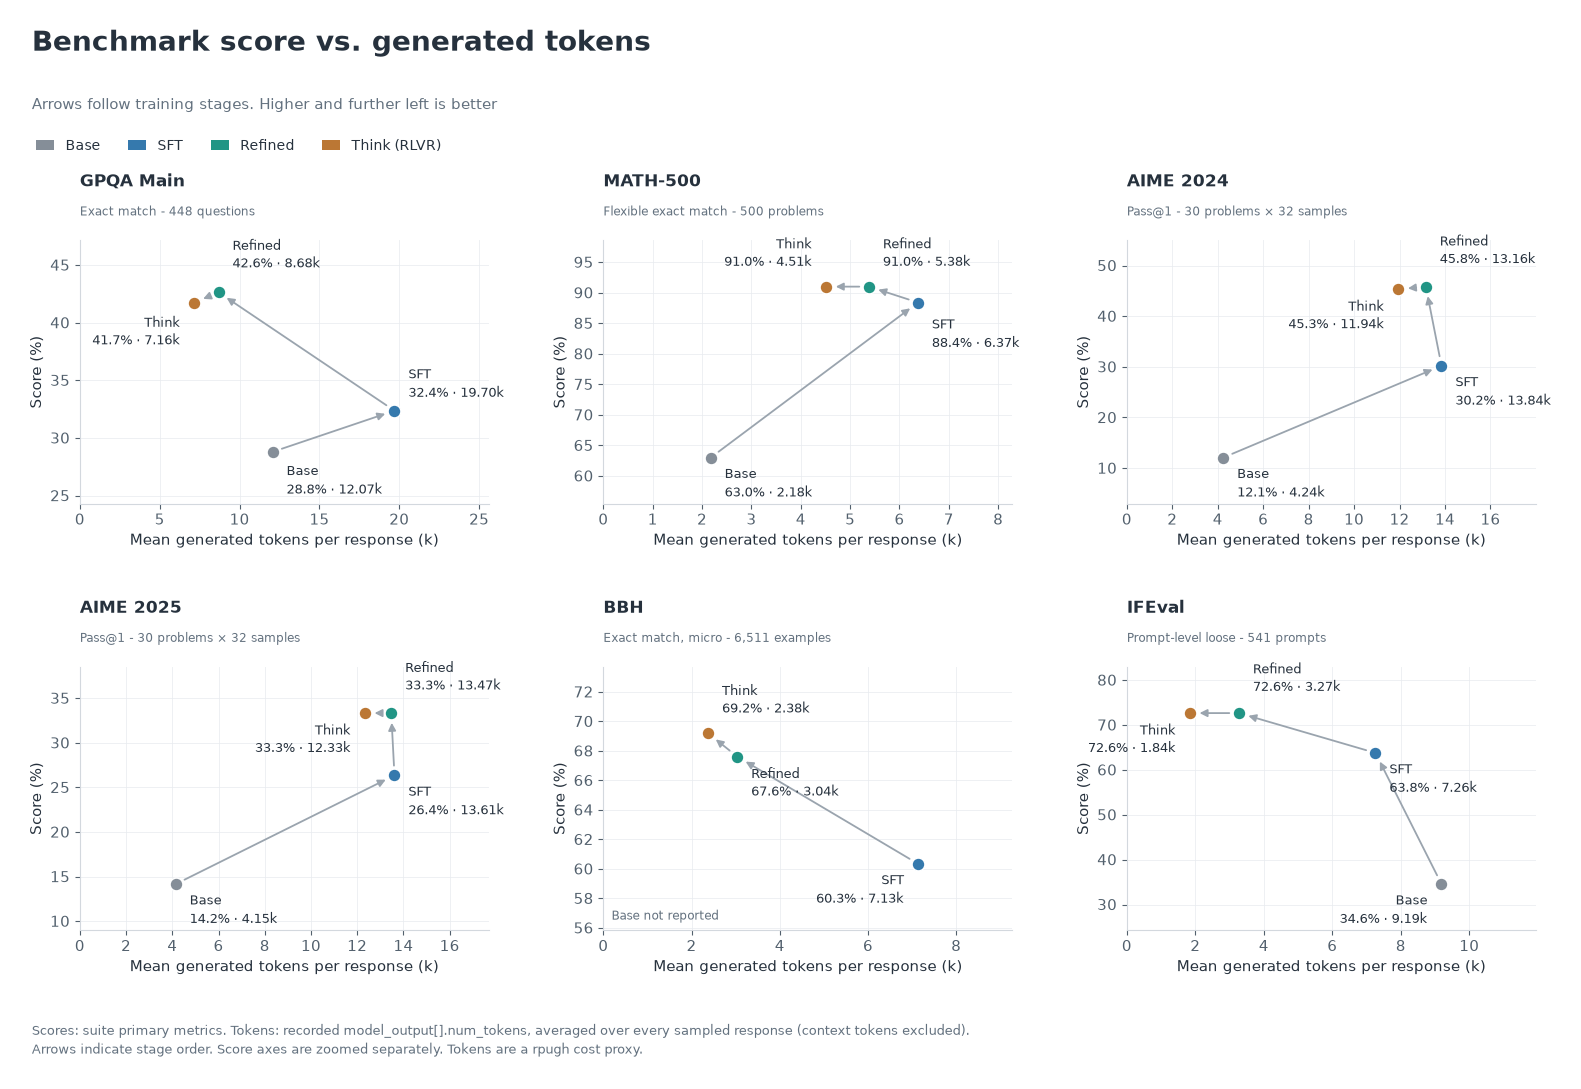

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(16, 11.4))
fig.subplots_adjust(
    left=0.065, right=0.975, top=0.745, bottom=0.14, wspace=0.28, hspace=0.62
)
fig.suptitle(
    "Benchmark score vs. generated tokens",
    x=0.035,
    y=0.93,
    ha="left",
    fontsize=20,
    fontweight="bold",
)
fig.text(
    0.035,
    0.87,
    "Arrows follow training stages. Higher and further left is better",
    va="top",
    fontsize=10.5,
    color="#63717F",
)
style.stage_legend(fig, y=0.845)
offsets = {
    "gpqa": {
        "Base": (10, -30),
        "SFT": (10, 10),
        "Refined": (10, 18),
        "Think (RLVR)": (-10, -30),
    },
    "math500": {
        "Base": (10, -28),
        "SFT": (10, -32),
        "Refined": (10, 15),
        "Think (RLVR)": (-10, 15),
    },
    "aime-2024": {
        "Base": (10, -28),
        "SFT": (10, -28),
        "Refined": (10, 17),
        "Think (RLVR)": (-10, -28),
    },
    "aime-2025": {
        "Base": (10, -28),
        "SFT": (10, -28),
        "Refined": (10, 17),
        "Think (RLVR)": (-10, -28),
    },
    "bbh": {"SFT": (-10, -28), "Refined": (10, -28), "Think (RLVR)": (10, 15)},
    "ifeval": {
        "Base": (-10, -28),
        "SFT": (10, -28),
        "Refined": (10, 16),
        "Think (RLVR)": (-10, -28),
    },
}
for ax, bench in zip(axes.flat, BENCHMARKS):
    measured = tokens[tokens.benchmark == bench].set_index("stage")
    measured = measured.reindex([stage for stage in STAGES if stage in measured.index])
    points = list(zip(measured.mean_tokens / 1000, measured.score))
    style.stage_arrows(ax, points)
    for stage, row in measured.iterrows():
        x, y = row.mean_tokens / 1000, row.score
        ax.scatter(
            x,
            y,
            s=85,
            color=COLORS[stage],
            edgecolor="white",
            linewidth=1,
            zorder=3,
        )
        offset = offsets[bench][stage]
        short = "Think" if stage == "Think (RLVR)" else stage
        ax.annotate(
            f"{short}\n{y:.1f}% · {x:.2f}k",
            (x, y),
            xytext=offset,
            textcoords="offset points",
            ha="right" if offset[0] < 0 else "left",
            fontsize=9,
            linespacing=1.4,
        )
    low, high = measured.score.min(), measured.score.max()
    padding = max((high - low) * 0.27, 4.5)
    ax.set(
        xlim=(0, measured.mean_tokens.max() / 1000 * 1.30),
        ylim=(max(0, low - padding), min(100, high + padding)),
        xlabel="Mean generated tokens per response (k)",
        ylabel="Score (%)",
    )
    ax.set_title(TITLES[bench], loc="left", pad=39)
    ax.text(
        0,
        1.095,
        METRIC_LABELS[bench],
        transform=ax.transAxes,
        fontsize=8.7,
        color="#63717F",
    )
    ref, final = measured.loc["Refined"], measured.loc["Think (RLVR)"]
    saving = 100 * (1 - final.mean_tokens / ref.mean_tokens)
    delta = final.score - ref.score
    if bench == "bbh":
        ax.text(
            0.02,
            0.04,
            "Base not reported",
            transform=ax.transAxes,
            fontsize=8.5,
            color="#63717F",
        )
    ax.grid(alpha=0.8)
style.footer(
    fig,
    "Scores: suite primary metrics. Tokens: recorded model_output[].num_tokens, averaged over every sampled response (context tokens excluded).\n"
    "Arrows indicate stage order. Score axes are zoomed separately. Tokens are a rpugh cost proxy.",
)
style.save(fig, FIGURES / "05_score_vs_token_cost")

## Benchmark averages

Equal weights across five benchmarks. BBH excluded because the Base run is incomplete.

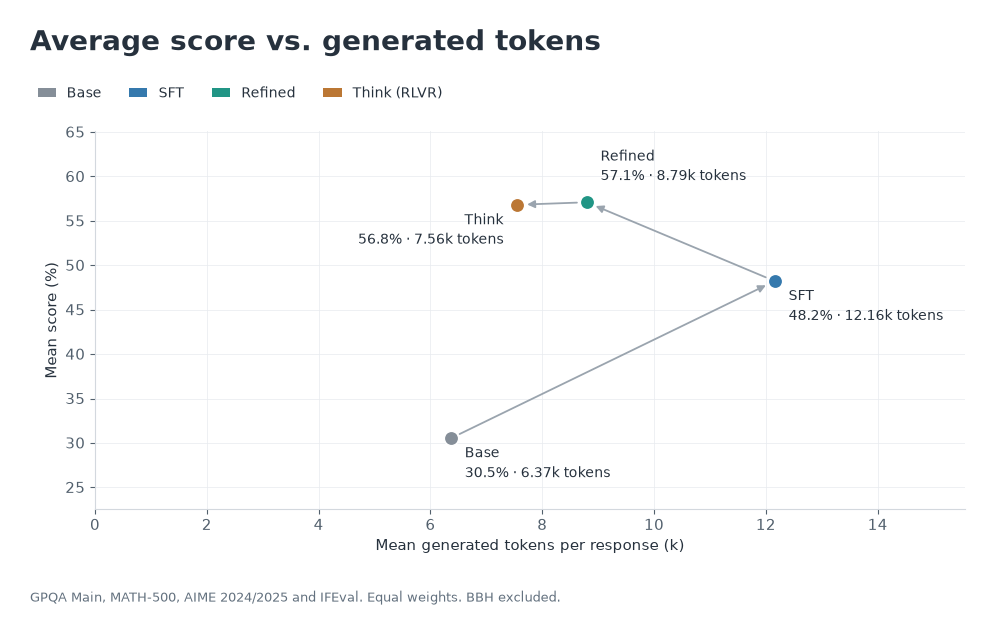

In [37]:
average_benchmarks = [b for b in BENCHMARKS if b != "bbh"]
shared = tokens[tokens.benchmark.isin(average_benchmarks)]
assert shared.groupby("stage").benchmark.nunique().reindex(STAGES).eq(5).all()
averages = shared.groupby("stage")[["score", "mean_tokens"]].mean().reindex(STAGES)

fig, ax = plt.subplots(figsize=(10, 6.4))
fig.subplots_adjust(left=0.10, right=0.97, top=0.77, bottom=0.18)
fig.suptitle(
    "Average score vs. generated tokens",
    x=0.035,
    y=0.93,
    ha="left",
    fontsize=20,
    fontweight="bold",
)
style.stage_legend(fig, y=0.86)
points = list(zip(averages.mean_tokens / 1000, averages.score))
style.stage_arrows(ax, points)
for stage, row in averages.iterrows():
    x, y = row.mean_tokens / 1000, row.score
    ax.scatter(
        x, y, s=105, color=COLORS[stage], edgecolor="white", linewidth=1, zorder=3
    )
    offset = {
        "Base": (10, -28),
        "SFT": (10, -28),
        "Refined": (10, 16),
        "Think (RLVR)": (-10, -28),
    }[stage]
    short = "Think" if stage == "Think (RLVR)" else stage
    ax.annotate(
        f"{short}\n{y:.1f}% · {x:.2f}k tokens",
        (x, y),
        xytext=offset,
        textcoords="offset points",
        ha="right" if offset[0] < 0 else "left",
        fontsize=10,
        linespacing=1.4,
    )
low, high = averages.score.min(), averages.score.max()
padding = max((high - low) * 0.30, 5)
ax.set(
    xlim=(0, averages.mean_tokens.max() / 1000 * 1.28),
    ylim=(max(0, low - padding), min(100, high + padding)),
    xlabel="Mean generated tokens per response (k)",
    ylabel="Mean score (%)",
)
ax.grid(alpha=0.8)
style.footer(
    fig, "GPQA Main, MATH-500, AIME 2024/2025 and IFEval. Equal weights. BBH excluded."
)
style.save(fig, FIGURES / "06_common_subset_score_cost")

## BBH tasks

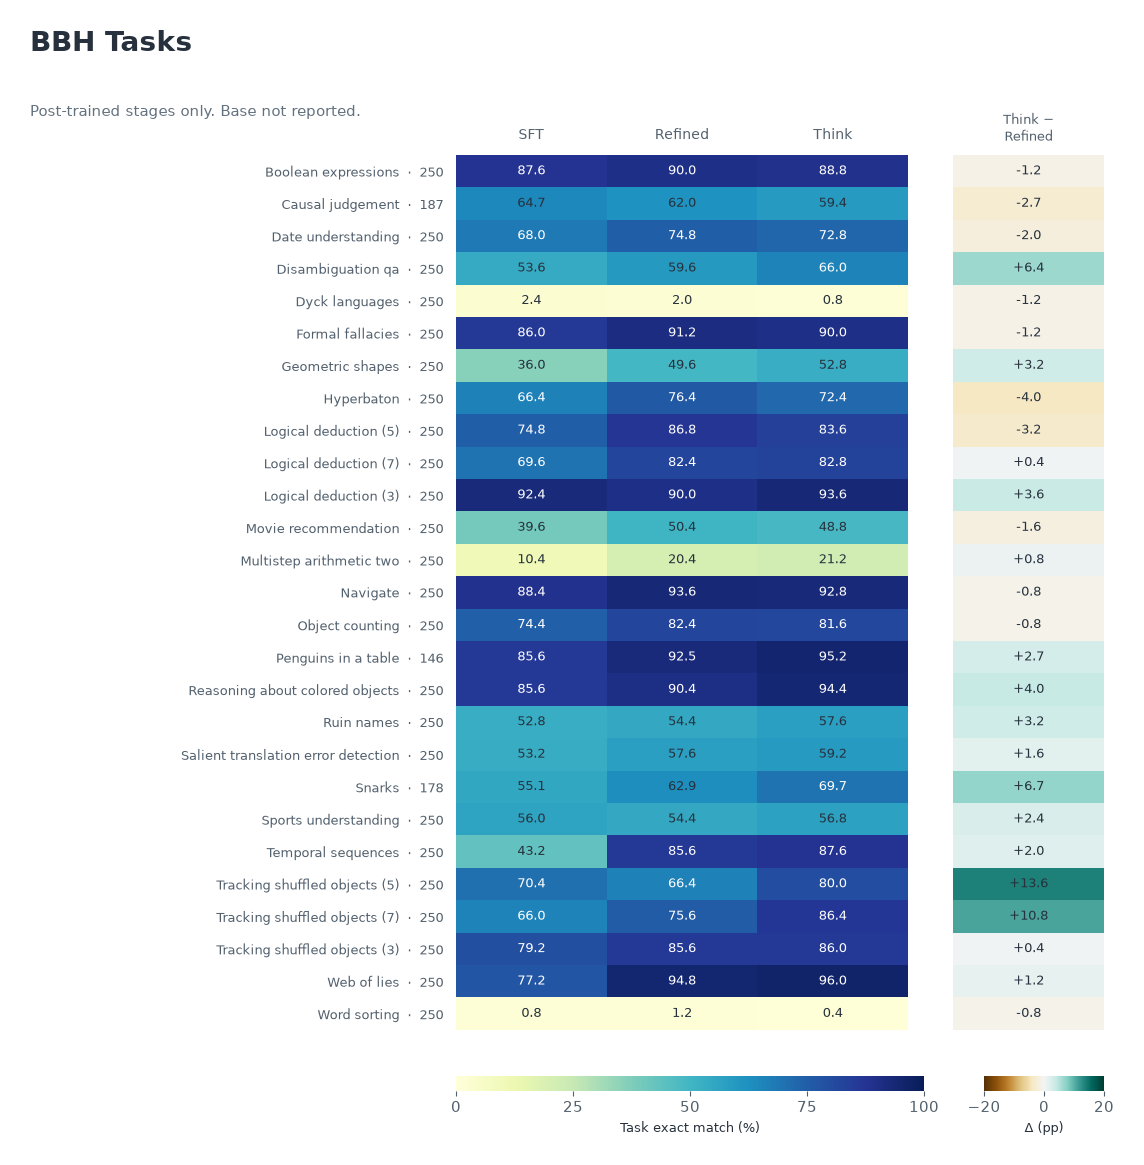

In [41]:
bbh_tasks = {}
for stage in STAGES[1:]:
    for task in runs[stage, "bbh"]["tasks"][1:]:
        name = task["alias"].split(":")[0].removeprefix("bbh_")
        bbh_tasks.setdefault(name, {"n": task["num_instances"]})[stage] = (
            100 * task["metrics"]["primary_score"]
        )
bbh = pd.DataFrame.from_dict(bbh_tasks, orient="index").sort_index()
bbh["Base"] = np.nan
bbh = bbh[STAGES + ["n"]]
mat = bbh[STAGES[1:]].to_numpy()
change = bbh["Think (RLVR)"] - bbh["Refined"]
fig = plt.figure(figsize=(12, 12.5))
gs = fig.add_gridspec(
    1,
    2,
    left=0.39,
    right=0.93,
    top=0.83,
    bottom=0.13,
    width_ratios=[3, 1],
    wspace=0.15,
)
ax = fig.add_subplot(gs[0])
dx = fig.add_subplot(gs[1])
fig.suptitle(
    "BBH Tasks",
    x=0.035,
    y=0.93,
    ha="left",
    fontsize=20,
    fontweight="bold",
)
fig.text(
    0.035,
    0.87,
    "Post-trained stages only. Base not reported.",
    va="top",
    fontsize=10.5,
    color="#63717F",
)
im = ax.imshow(
    np.ma.masked_invalid(mat), cmap="YlGnBu", vmin=0, vmax=100, aspect="auto"
)
for (i, j), v in np.ndenumerate(mat):
    if np.isfinite(v):
        ax.text(
            j,
            i,
            f"{v:.1f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if v >= 65 else "#26313D",
        )
labels = []
for name, row in bbh.iterrows():
    label = name.replace("_", " ").capitalize()
    label = (
        label.replace(
            "Tracking shuffled objects three objects",
            "Tracking shuffled objects (3)",
        )
        .replace(
            "Tracking shuffled objects five objects",
            "Tracking shuffled objects (5)",
        )
        .replace(
            "Tracking shuffled objects seven objects",
            "Tracking shuffled objects (7)",
        )
    )
    label = (
        label.replace("Logical deduction three objects", "Logical deduction (3)")
        .replace("Logical deduction five objects", "Logical deduction (5)")
        .replace("Logical deduction seven objects", "Logical deduction (7)")
    )
    labels.append(f"{label}  ·  {int(row['n'])}")
ax.set_yticks(range(len(bbh)), labels, fontsize=9.3)
ax.set_xticks(range(3), ["SFT", "Refined", "Think"], fontsize=10)
ax.xaxis.tick_top()
ax.tick_params(length=0, pad=9)
dm = dx.imshow(
    change.to_numpy()[:, None],
    cmap="BrBG",
    norm=TwoSlopeNorm(vmin=-20, vcenter=0, vmax=20),
    aspect="auto",
)
for i, v in enumerate(change):
    dx.text(
        0,
        i,
        f"{v:+.1f}",
        ha="center",
        va="center",
        fontsize=9,
        color="white" if abs(v) > 14 else "#26313D",
    )
dx.set_yticks([])
dx.set_xticks([0], ["Think −\nRefined"], fontsize=9.5)
dx.xaxis.tick_top()
dx.tick_params(length=0, pad=7)
for a in [ax, dx]:
    for sp in a.spines.values():
        sp.set_visible(False)
cax = fig.add_axes([0.39, 0.081, 0.39, 0.012])
cb = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[0, 25, 50, 75, 100])
cb.set_label("Task exact match (%)", fontsize=9)
cb.outline.set_visible(False)
cax2 = fig.add_axes([0.83, 0.081, 0.10, 0.012])
cb2 = fig.colorbar(dm, cax=cax2, orientation="horizontal", ticks=[-20, 0, 20])
cb2.set_label("Δ (pp)", fontsize=9)
cb2.outline.set_visible(False)

style.save(fig, FIGURES / "07_bbh_task_breakdown")

## IFEval

Prompt-level accuracy requires all instructions to pass; instruction-level accuracy scores each instruction separately.

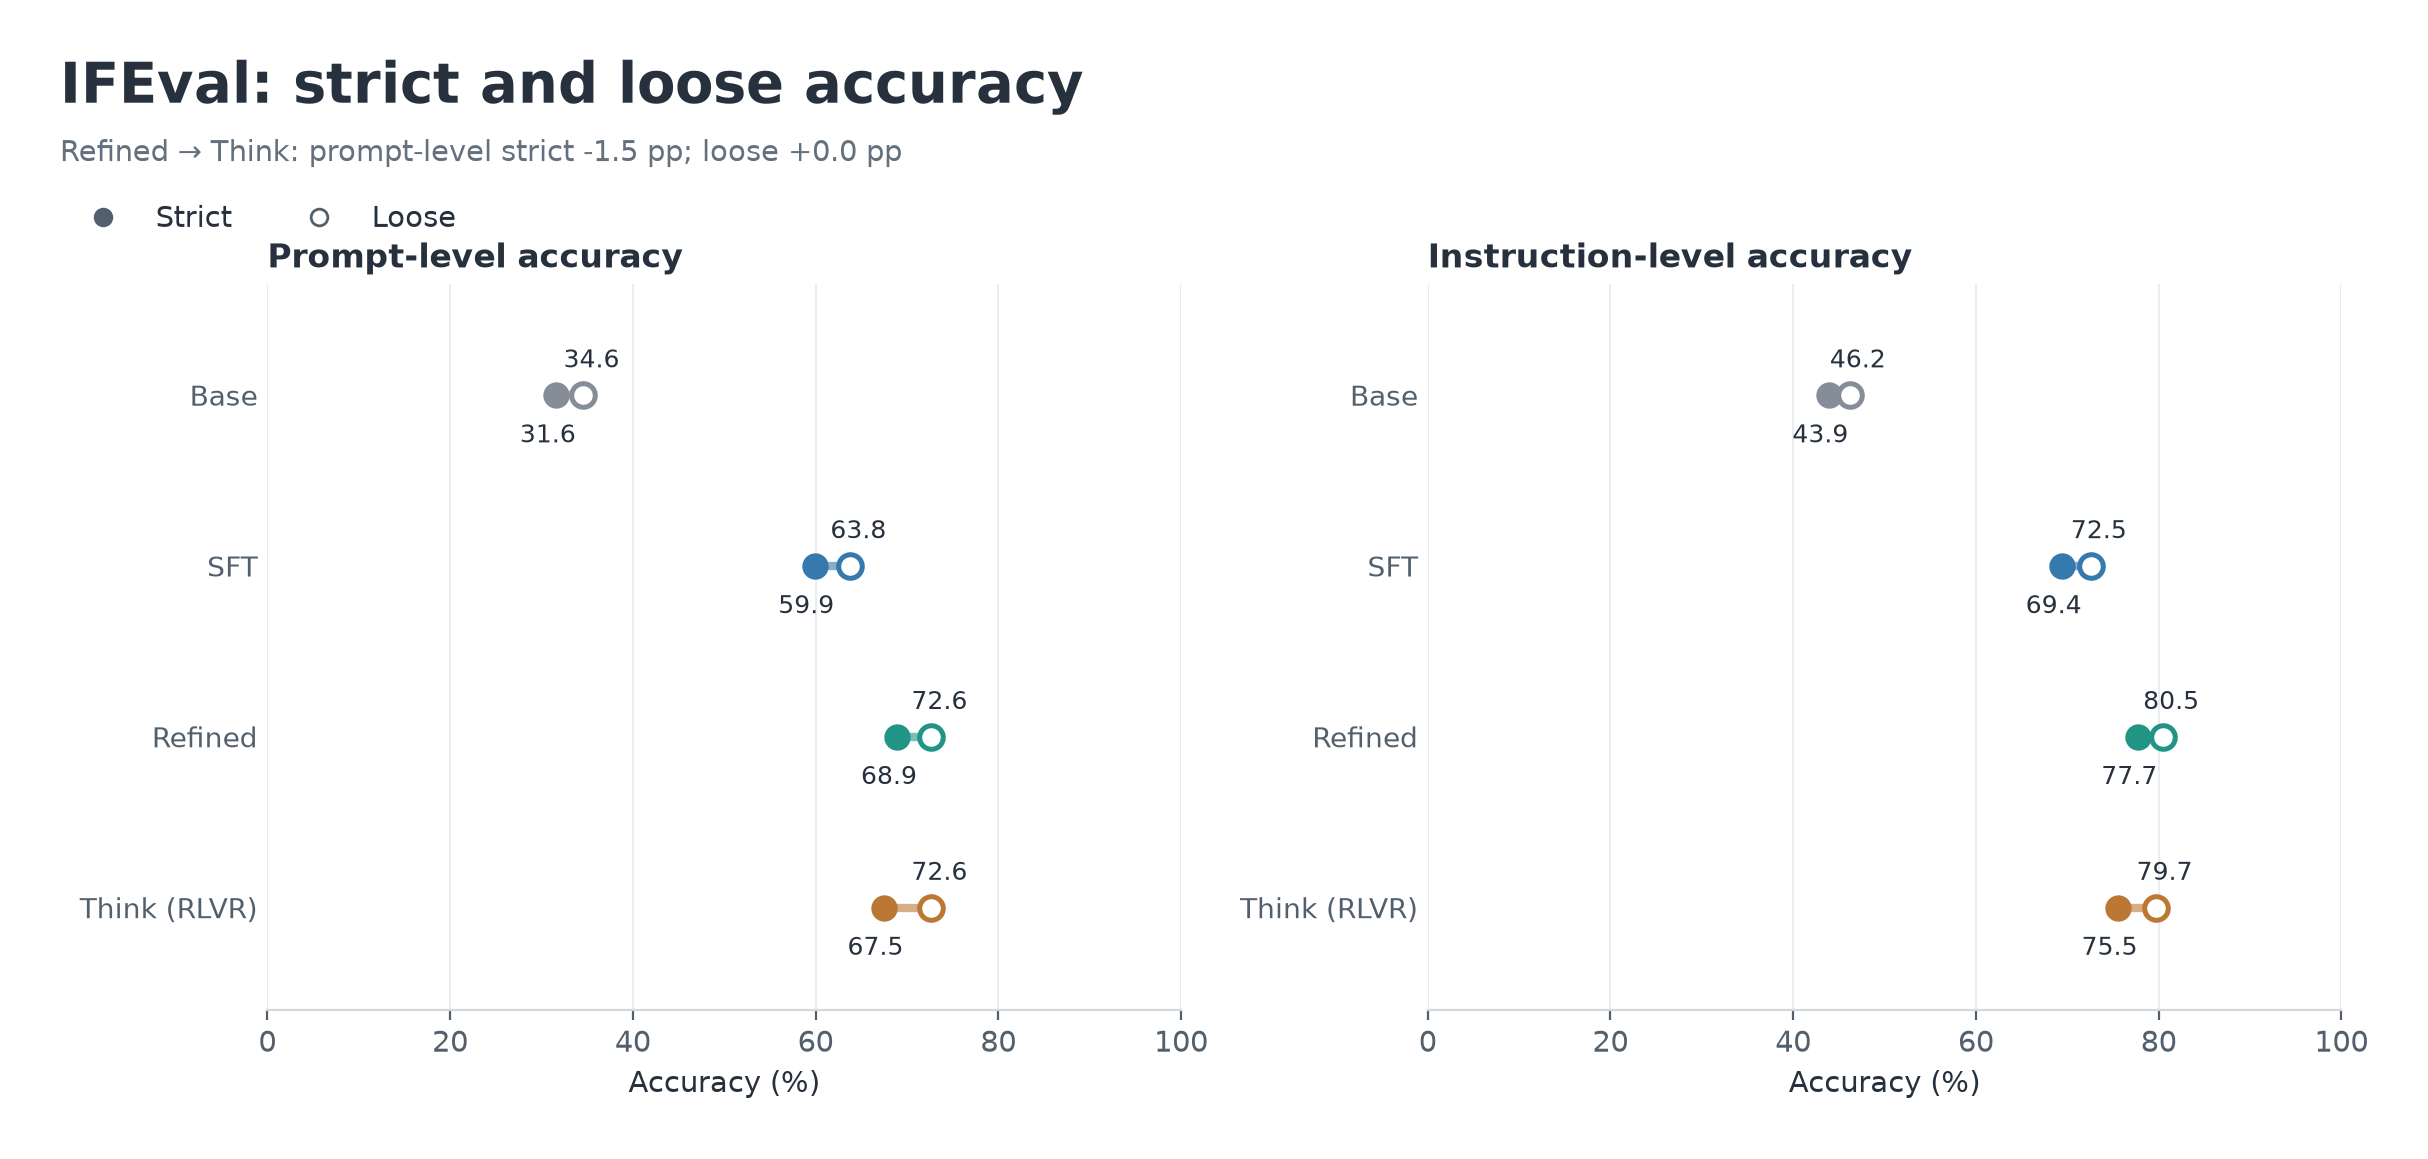

In [ ]:
ifeval_rows = []
for level in ["prompt", "inst"]:
    for stage in STAGES:
        instruction_metrics = runs[stage, "ifeval"]["tasks"][0]["metrics"]
        ifeval_rows.append(
            {
                "stage": stage,
                "level": level,
                "strict": 100 * instruction_metrics[f"{level}_level_strict_acc"],
                "loose": 100 * instruction_metrics[f"{level}_level_loose_acc"],
            }
        )
ifeval = pd.DataFrame(ifeval_rows)
values = ifeval.set_index(["stage", "level"])
fig, axes = plt.subplots(1, 2, figsize=(12.2, 6.6))
fig.subplots_adjust(left=0.12, right=0.97, top=0.76, bottom=0.21, wspace=0.27)
fig.suptitle(
    "IFEval: strict and loose accuracy",
    x=0.035,
    y=0.93,
    ha="left",
    fontsize=20,
    fontweight="bold",
)
prompt_change = (
    values.loc[("Think (RLVR)", "prompt")] - values.loc[("Refined", "prompt")]
)
fig.text(
    0.035,
    0.87,
    f"Refined → Think: prompt-level strict {prompt_change['strict']:+.1f} pp; loose {prompt_change['loose']:+.1f} pp",
    va="top",
    fontsize=10.5,
    color="#63717F",
)
for ax, level, title in zip(
    axes,
    ["prompt", "inst"],
    ["Prompt-level accuracy", "Instruction-level accuracy"],
):
    for i, s in enumerate(STAGES):
        row = values.loc[(s, level)]
        strict, loose = row["strict"], row["loose"]
        ax.plot([strict, loose], [i, i], color=COLORS[s], lw=3, alpha=0.6)
        ax.scatter(strict, i, s=72, color=COLORS[s], zorder=3)
        ax.scatter(
            loose, i, s=72, facecolor="white", edgecolor=COLORS[s], lw=1.8, zorder=4
        )
        ax.annotate(
            f"{strict:.1f}",
            (strict, i),
            xytext=(-3, -17),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )
        ax.annotate(
            f"{loose:.1f}",
            (loose, i),
            xytext=(3, 10),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )
    ax.set_yticks(range(4), STAGES, fontsize=10)
    ax.set(xlim=(0, 100), ylim=(3.6, -0.65), xticks=np.arange(0, 101, 20))
    ax.set_title(title, loc="left")
    ax.set_xlabel("Accuracy (%)")
    ax.grid(axis="x")
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.legend(
    handles=[
        Line2D([0], [0], marker="o", linestyle="none", color="#52606D", label="Strict"),
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor="white",
            markeredgecolor="#52606D",
            label="Loose",
        ),
    ],
    loc="upper left",
    bbox_to_anchor=(0.03, 0.84),
    frameon=False,
    ncol=2,
)

style.save(fig, FIGURES / "08_ifeval_strict_loose")